# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import USTCSmokeRSDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/",
    "csv_file": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = USTCSmokeRSDataset(dataset_config)

## Show images from the dataset

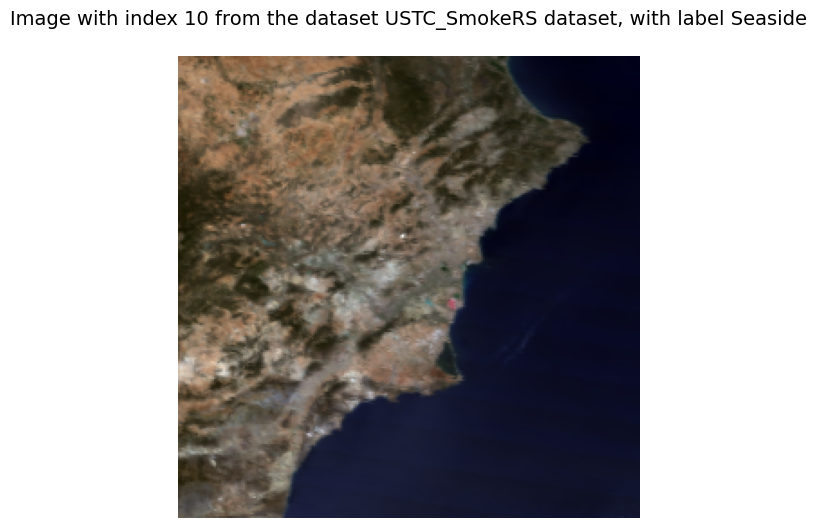

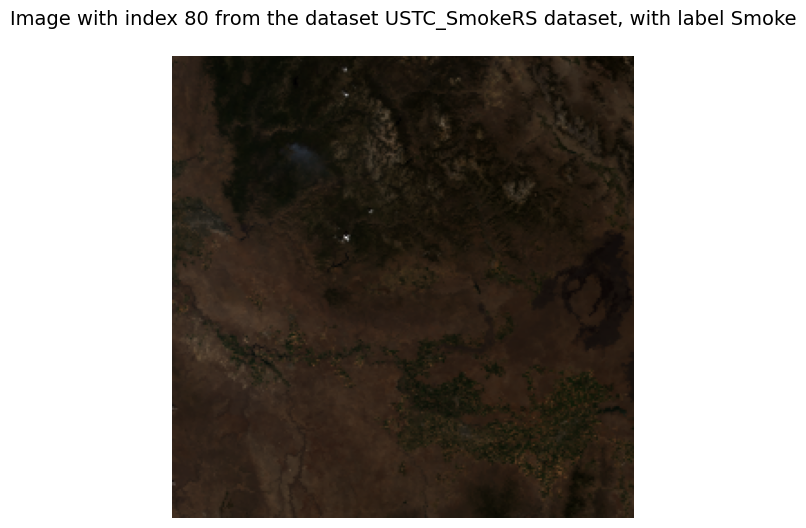

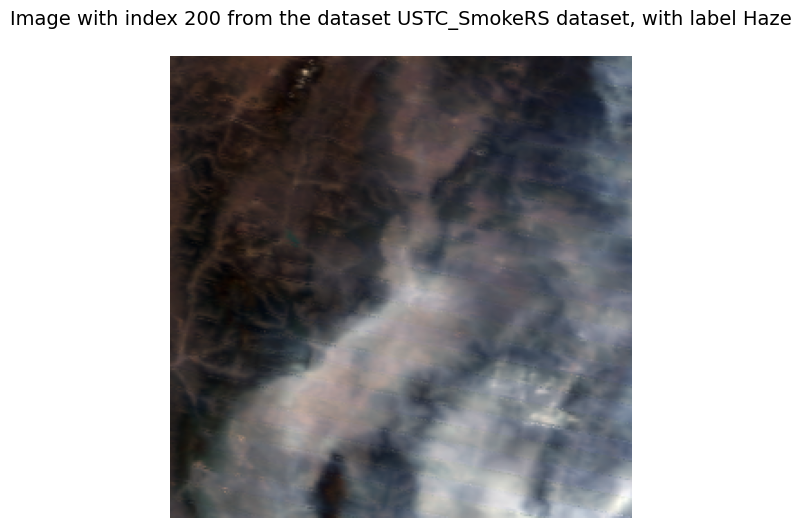

In [5]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

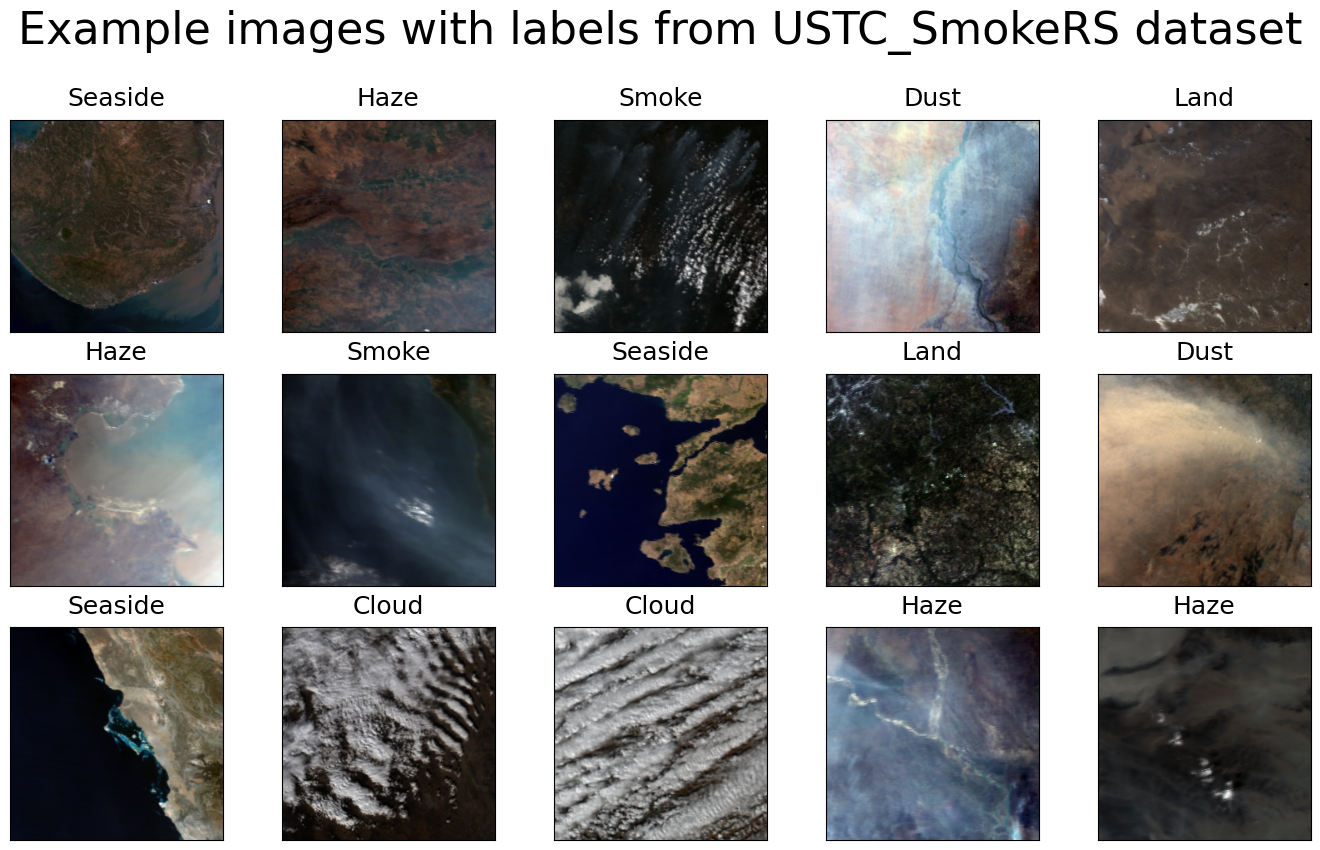

In [6]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [7]:
dataset.show_samples()

,File name,Label
0,Haze/haze_4.tif,Haze
1,Haze/haze_863.tif,Haze
2,Smoke/smoke_403.tif,Smoke
3,Land/land_662.tif,Land
4,Land/land_122.tif,Land
5,Haze/haze_294.tif,Haze
6,Haze/haze_596.tif,Haze
7,Cloud/cloud_984.tif,Cloud
8,Haze/haze_120.tif,Haze
9,Cloud/cloud_891.tif,Cloud


In [8]:
dataset.data_distribution_table()

,Label,Count
0,Cloud,923
1,Dust,797
2,Haze,802
3,Land,823
4,Seaside,806
5,Smoke,830


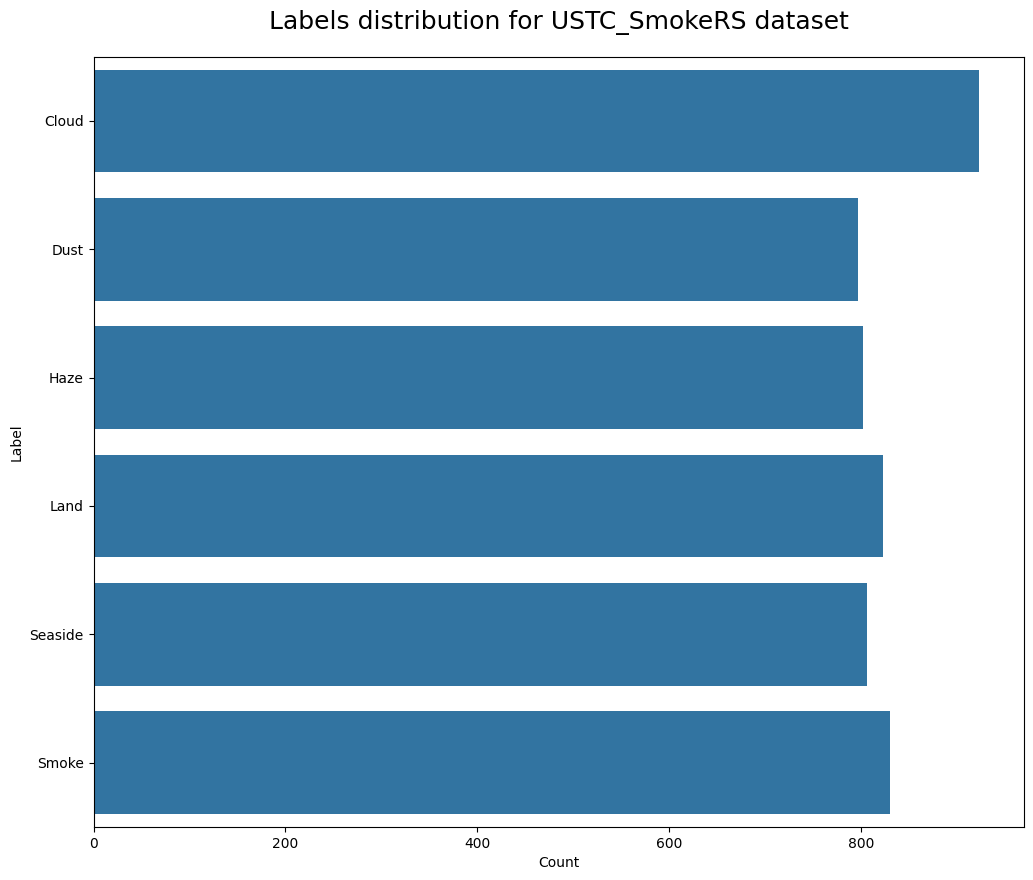

In [9]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [10]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/",
    "csv_file": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/train.csv",
}

train_dataset = USTCSmokeRSDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/",
    "csv_file": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = USTCSmokeRSDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(4981, 622)

## Setup and create the model for training

In [11]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-14 11:04:15,145 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-14 11:04:15,386 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [12]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-14 11:04:17,196 INFO Starting training.
training: 100%|██████████| 156/156 [02:08<00:00,  1.22it/s]
2025-05-14 11:06:25,757 INFO epoch: 1, time: 128, loss:  0.51032
testing on train set: 100%|██████████| 156/156 [00:47<00:00,  3.31it/s]
2025-05-14 11:07:14,684 INFO Accuracy:0.9457940172656093, Precision Micro:0.9457940172656093, Precision Macro:0.948118914423642, Precision Weighted:0.9488034059889852, Precision per Class:[0.99553571 0.93489583 0.9676512  0.96014493 0.98168498 0.84880083], Recall Micro:0.9457940172656093, Recall Macro:0.9448945256340862, Recall Weighted:0.9457940172656094, Recall per Class:[0.96641387 0.90087829 0.85785536 0.96597813 0.99751861 0.98072289], F1_score Micro:0.9457940172656087, F1_score Macro:0.945063118532507, F1_score Weighted:0.9458723311794366, F1_score per Class:[0.98075866 0.91757188 0.90945142 0.9630527  0.98953846 0.91000559]
testing on validation set: 100%|██████████| 20/20 [00:06<00:00,  3.21it/s]
2025-05-14 11:07:20,926 INFO Accuracy:0.9

0.07881870010579399

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/",
    "csv_file": "/home/dragik/data/FAIR_EO/USTC_SmokeRS/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = USTCSmokeRSDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-14 12:03:13,892 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/checkpoint.pth.tar
2025-05-14 12:03:15,229 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 39/39 [00:06<00:00,  5.71it/s]


[{'Accuracy': 0.9678456591639871},
 {'Precision Micro': 0.9678456591639871,
  'Precision Macro': 0.9657239264653948,
  'Precision Weighted': 0.9679174577311597,
  'Precision per Class': array([0.98373984, 0.93877551, 0.92553191, 0.99074074, 1.        ,
         0.95555556])},
 {'Recall Micro': 0.9678456591639871,
  'Recall Macro': 0.9652371984866613,
  'Recall Weighted': 0.9678456591639872,
  'Recall per Class': array([0.99180328, 0.95833333, 0.93548387, 1.        , 0.99090909,
         0.91489362])},
 {'F1_score Micro': 0.9678456591639866,
  'F1_score Macro': 0.9653758715949979,
  'F1_score Weighted': 0.9677846236218399,
  'F1_score per Class': array([0.9877551 , 0.94845361, 0.93048128, 0.99534884, 0.99543379,
         0.93478261])}]

## Predictions

2025-05-14 12:03:22,081 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/checkpoint.pth.tar
2025-05-14 12:03:23,358 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/checkpoint.pth.tar at epoch 21


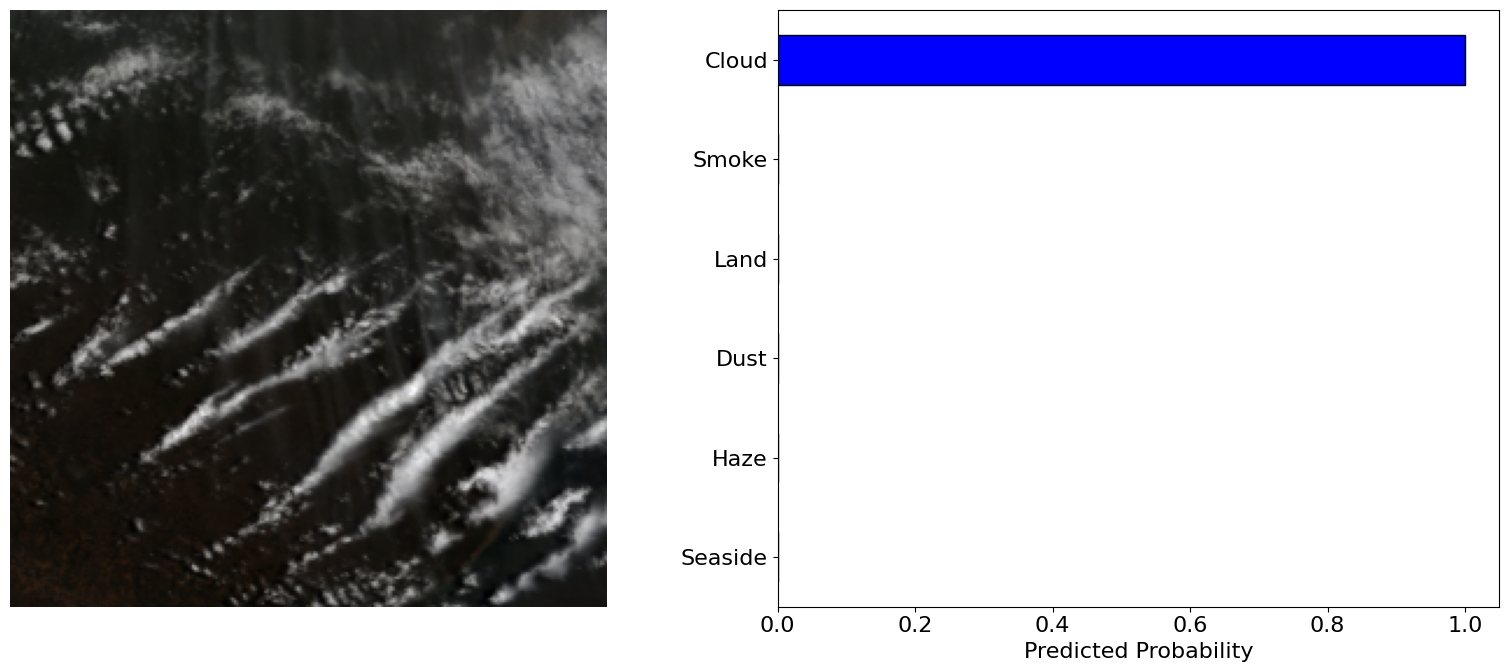

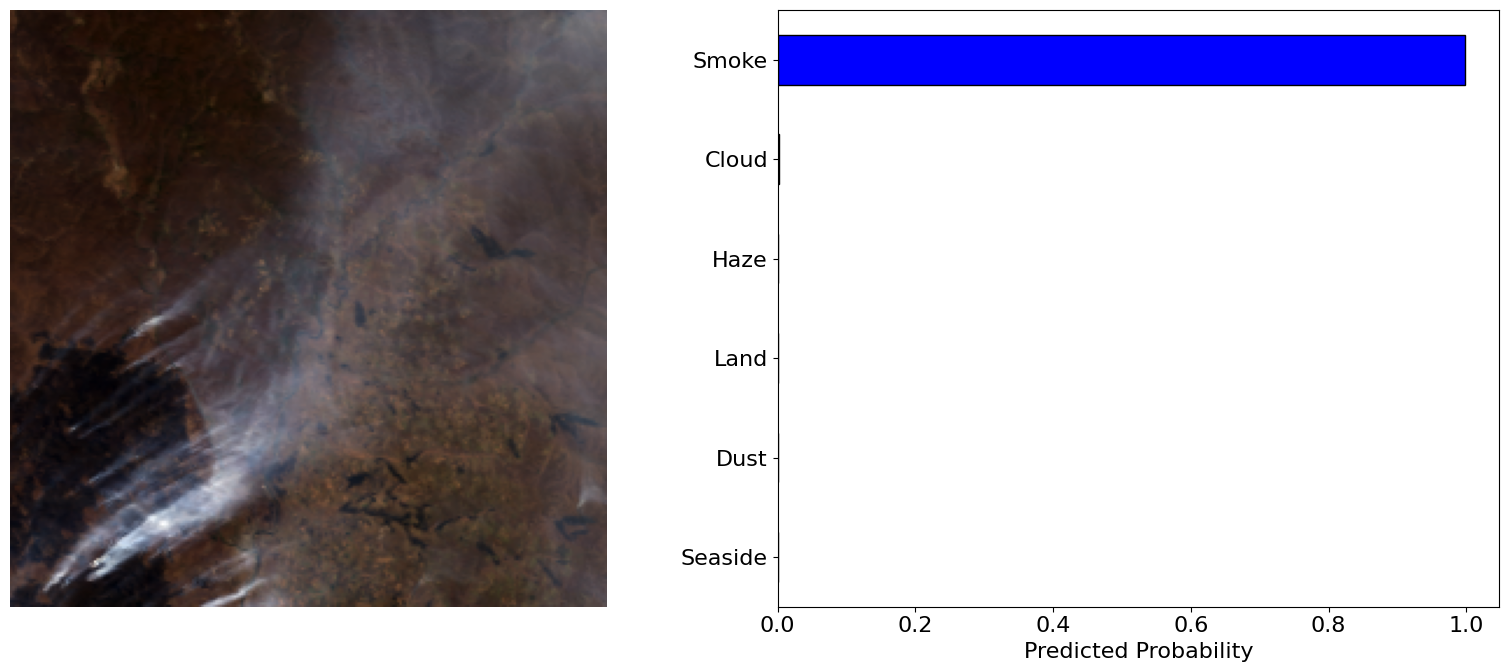

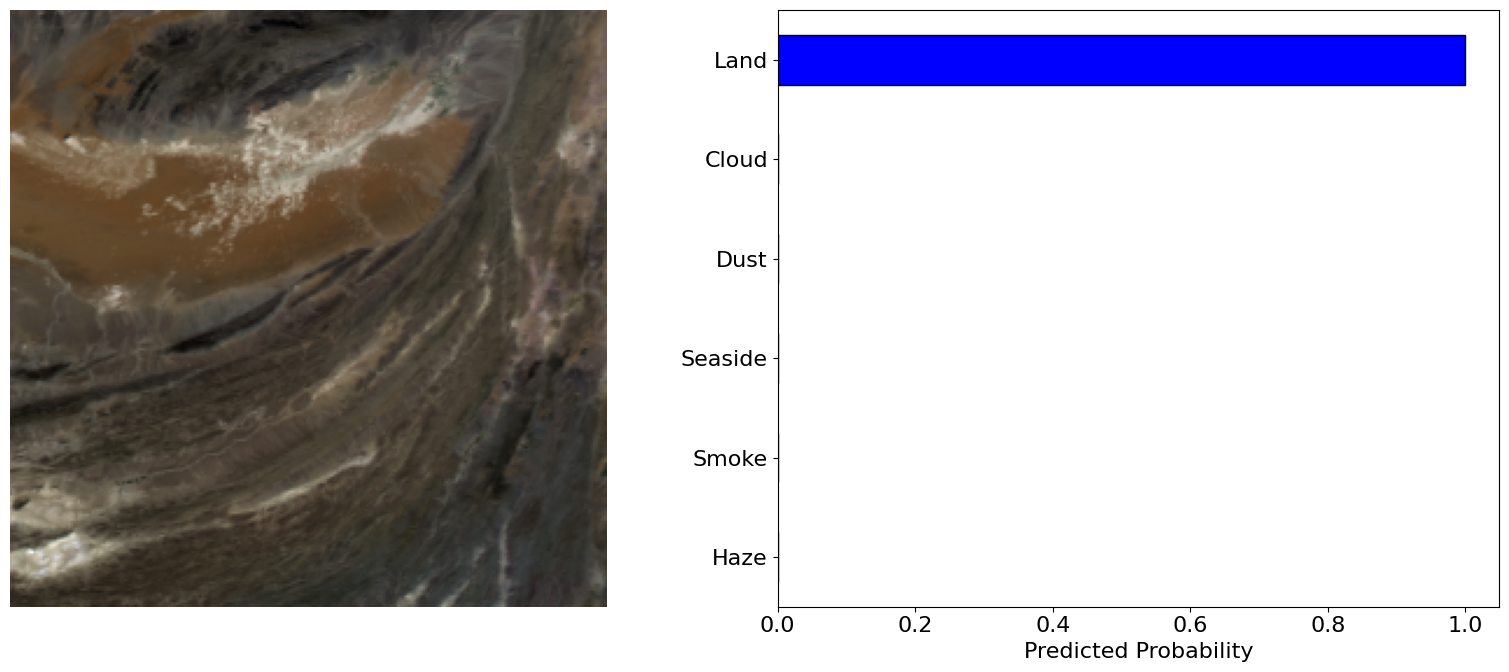

In [14]:
labels = ["Cloud","Dust","Haze","Land","Seaside","Smoke"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/USTC_SmokeRS/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/USTC_SmokeRS/Cloud/cloud_1156.tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/USTC_SmokeRS/Smoke/smoke_12.tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/USTC_SmokeRS/Land/land_685.tif')
fig = model.predict_image(image, labels, transform)